# Training and comparing three architectures

U-Net, DeepLabV3+ and SegFormer, written from scratch and trained the same way on Sentinel-1 radar tiles. Run top to bottom once per model; needs PyTorch with CUDA.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent            # notebooks/ sits one level below the project
sys.path.insert(0, str(ROOT))               # so config.py and the packages are importable

import json
import re
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn
from tqdm import tqdm

import config
from training.model import build_model, count_parameters   # the one file kept outside the notebook


def progress(iterable=None, **kw):
    """A text progress bar that shows in every notebook viewer.

    tqdm's widget bar needs a front-end extension and silently shows nothing
    without one; the text bar always works. Written to stdout, so the notebook
    doesn't style it as an error.
    """
    return tqdm(iterable, file=sys.stdout, ncols=120, **kw)


DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", DEVICE,
      f"({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else "- NO GPU, this will be slow")

torch 2.5.1+cu121 | device: cuda (NVIDIA GeForce RTX 3050 Laptop GPU)


## Settings

Set MODEL, run top to bottom, then change MODEL and run again - everything else is shared, so the three are trained identically.

In [2]:
MODEL = "segformer"    # "unet", "deeplab" or "segformer" - one notebook per model
EPOCHS = 40                # every epoch runs - no early stopping; the best epoch is kept
BATCH = 16                 # drop to 8 if the 4 GB card runs out of memory
LR = 3e-4
WARMUP = 2                 # epochs of gentle start before the full learning rate
EMA_DECAY = 0.999          # weight averaging: remembers ~1,000 steps (~3 epochs)
CLIP = 1.0                 # cap on the size of any one step's gradient
RESUME = True
WEIGHT_CAP = 20.0          # rarest class at most this many times the commonest
OVERFIT_EPOCHS = 400       # overfit test: 10 tiles x 400 epochs = 1,200 steps, a minute or two

# unet keeps the name of the run already done; the other two are named as they are.
NAME = "unet16" if MODEL == "unet" else MODEL
TILES = config.TILES
print(f"run '{NAME}': {MODEL}, tiles from {TILES.relative_to(config.ROOT)}")

run 'segformer': segformer, tiles from data\tiles


## The data, with radar-specific augmentation

Loads the 128x128 radar tiles and augments the training ones with flips, quarter-turns, speckle and a brightness shift.

In [3]:
class Tiles(Dataset):
    """Tiles from one split, with radar-specific augmentation for training."""

    def __init__(self, split, augment=False, limit=None, root=TILES, files=None):
        self.files = list(files) if files is not None else sorted((root / split).glob("*.npz"))
        if limit:
            self.files = self.files[:limit]
        if not self.files:
            raise SystemExit(f"No tiles in {root / split}. Run training/build_dataset.py first.")
        self.augment = augment
        self.rng = np.random.default_rng(0)

    def __len__(self):
        return len(self.files)

    def __getitem__(self, index):
        with np.load(self.files[index]) as data:
            x = data["x"].astype("float32")
            y = data["y"].astype("int64")

        if self.augment:
            if self.rng.random() < 0.5:                       # flips and turns
                x, y = x[:, :, ::-1], y[:, ::-1]
            if self.rng.random() < 0.5:
                x, y = x[:, ::-1, :], y[::-1, :]
            turns = int(self.rng.integers(4))
            if turns:
                x = np.rot90(x, turns, axes=(1, 2))
                y = np.rot90(y, turns)
            x = x * self.rng.normal(1.0, 0.05, x.shape).astype("float32")   # speckle
            x = x + self.rng.normal(0.0, 0.02)                             # calibration
            x = np.clip(x, 0.0, 1.0)

        return (torch.from_numpy(np.ascontiguousarray(x)),
                torch.from_numpy(np.ascontiguousarray(y)))

## Class weights

Weights the loss by how rare each class is, capped at 20x so one scarce class cannot dominate.

In [4]:
def class_weights(loader, cap=WEIGHT_CAP):
    """Capped inverse-frequency weights, averaging 1, cached between runs.

    The cache is discarded when the tiles are newer than it. Counting takes a
    minute; reusing counts from a dataset that has since been rebuilt would
    weight the loss for tiles that no longer exist, and nothing would say so.
    """
    cache = config.OUTPUTS / "class_weights.json"
    manifest = TILES / "manifest.csv"
    fresh = (cache.exists() and manifest.exists()
             and cache.stat().st_mtime >= manifest.stat().st_mtime)

    if fresh:
        counts = np.array(json.loads(cache.read_text()), dtype="float64")
        fresh = len(counts) == config.NUM_CLASSES       # counted for an older class list
    if not fresh:
        if cache.exists():
            print("   tiles are newer than the cached counts - counting again")
        counts = np.zeros(config.NUM_CLASSES, dtype="float64")
        for _, y in progress(loader, desc="counting classes (once)", unit="batch"):
            counts += np.bincount(y.numpy().ravel(), minlength=config.NUM_CLASSES)
        config.OUTPUTS.mkdir(parents=True, exist_ok=True)
        cache.write_text(json.dumps(counts.tolist()))

    present = counts[1:] > 0
    inverse = np.zeros(config.NUM_CLASSES - 1, dtype="float64")
    inverse[present] = counts[1:][present].sum() / counts[1:][present]
    floor = inverse[present].min()                         # cap BEFORE normalising
    squashed = int((inverse[present] > floor * cap).sum())
    capped = np.minimum(inverse[present], floor * cap)
    inverse[present] = capped / capped.mean()

    weights = np.zeros(config.NUM_CLASSES, dtype="float32")
    weights[1:] = inverse
    if squashed:
        raw = counts[1:][present].max() / counts[1:][present].min()
        print(f"   capped {squashed} class weight(s) at {cap:.0f}x (raw imbalance was {raw:.0f}x)")
    print("   loss weights: " + "  ".join(
        f"{config.CLASSES[i][:8]} {weights[i]:.2f}" for i in range(1, config.NUM_CLASSES)))
    return torch.tensor(weights, device=DEVICE)

## Scoring

Mean IoU and accuracy over labelled pixels only, averaged across the classes present.

In [5]:
@torch.no_grad()
def evaluate(net, loader, classes=config.NUM_CLASSES, desc=None):
    """Confusion matrix over labelled pixels, then IoU per class.
    With `desc`, shows its own progress bar."""
    net.eval()
    matrix = np.zeros((classes, classes), dtype="int64")
    for x, y in (progress(loader, desc=desc, unit="batch") if desc else loader):
        x, y = x.to(DEVICE), y.to(DEVICE)
        predicted = net(x).argmax(1)
        keep = y > 0
        if keep.any():
            np.add.at(matrix, (y[keep].cpu().numpy(), predicted[keep].cpu().numpy()), 1)

    ious = {}
    for c in range(1, classes):
        if matrix[c, :].sum() > 0:
            hit = matrix[c, c]
            union = matrix[c, :].sum() + matrix[:, c].sum() - hit
            ious[c] = hit / union if union else 0.0
    mean_iou = float(np.mean(list(ious.values()))) if ious else 0.0
    accuracy = float(np.trace(matrix) / max(matrix.sum(), 1))
    return mean_iou, accuracy, ious, matrix


def show(title, ious, matrix):
    print(f"\n{title}")
    for c, value in sorted(ious.items()):
        seen = matrix[c, :].sum()
        thin = "   <-- too few examples to learn" if seen < 20000 else ""
        print(f"   {config.CLASSES[c]:<24}{100 * value:>6.1f}%{seen:>12,} px{thin}")

## Checkpoints that survive a crash

Saves weights, optimiser and schedule atomically every epoch: `_last.pt` to resume from, `_best.pt` to use.

In [6]:
def save_atomically(payload, path):
    """Write beside the target, then rename: the file is old or new, never torn."""
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(".tmp")
    torch.save(payload, tmp)
    tmp.replace(path)

## The training loop

Trains every epoch (no early stopping), scores a running average of the weights after each one, keeps the best, then scores that on validation and test.

In [7]:
RECIPE = "nine-classes-full-epochs-ema"   # a checkpoint from any other recipe is not resumed


def spread_tiles(n, root=TILES, month="07"):
    """One tile from each of the first n training regions, all from the same month.

    The overfit test used to take the first n files alphabetically: all Amazon,
    all January, with two classes under 1% of the pixels. Averaged over
    classes, those two alone held the score near 50% however well the rest was
    learned. One tile per region puts every class in.
    """
    by_region = {}
    for f in sorted((root / "train").glob(f"*_{config.YEAR}-{month}_*.npz")):
        match = re.match(r"^(.*)_\d{4}-\d{2}_r\d+_c\d+$", f.stem)   # match the shape,
        if match:                                                     # not the underscores
            by_region.setdefault(match.group(1), []).append(f)
    return [files[len(files) // 2] for _, files in sorted(by_region.items())][:n]


def train_model(epochs=EPOCHS, batch=BATCH, lr=LR, model=MODEL, name=NAME,
                overfit=0, resume=RESUME):
    root = TILES

    if overfit:
        train_set = Tiles("train", files=spread_tiles(overfit, root), root=root)
        val_set = train_set                   # the same tiles, on purpose
        epochs = OVERFIT_EPOCHS
        resume = False
        print(f"OVERFIT TEST on {len(train_set)} tiles from {len(train_set)} regions, no augmentation,")
        print(f"{epochs} epochs at a constant learning rate. Expect close to 100% of pixels right.\n")
    else:
        train_set = Tiles("train", augment=True, root=root)
        val_set = Tiles("val", root=root)
        print(f"train {len(train_set)} tiles   val {len(val_set)} tiles")

    train_loader = DataLoader(train_set, batch_size=batch, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_set, batch_size=batch)

    net = build_model(model, classes=config.NUM_CLASSES).to(DEVICE)
    print(f"{model}: {count_parameters(net):,} parameters")

    weights = class_weights(DataLoader(Tiles("train", root=root), batch_size=batch))
    criterion = nn.CrossEntropyLoss(weight=weights, ignore_index=0)  # unlabelled ignored
    optimiser = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=1e-4)

    if overfit:
        # Memorising needs a steady push, not a schedule that fades to zero.
        schedule = torch.optim.lr_scheduler.LambdaLR(optimiser, lambda e: 1.0)
        ema = None
    else:
        # A gentle start, then a cosine fade to 1% of LR across ALL the epochs.
        # Without early stopping the fade completes, so the last epochs settle
        # instead of being cut off while the steps are still large.
        schedule = torch.optim.lr_scheduler.SequentialLR(optimiser, [
            torch.optim.lr_scheduler.LinearLR(optimiser, start_factor=0.1, total_iters=WARMUP),
            torch.optim.lr_scheduler.CosineAnnealingLR(optimiser, epochs - WARMUP, eta_min=lr * 0.01),
        ], milestones=[WARMUP])
        # A slowly moving average of the weights. Each step's weights are one
        # noisy snapshot; the average over the last ~1,000 steps is what gets
        # scored every epoch and saved as the best.
        ema = AveragedModel(net, multi_avg_fn=get_ema_multi_avg_fn(EMA_DECAY), use_buffers=True)

    config.WEIGHTS.mkdir(parents=True, exist_ok=True)
    config.OUTPUTS.mkdir(parents=True, exist_ok=True)
    last_path = config.WEIGHTS / f"{name}_last.pt"
    best_path = config.WEIGHTS / f"{name}_best.pt"
    best, history, first_epoch = -1.0, [], 1

    if resume and last_path.exists():
        saved = torch.load(last_path, map_location=DEVICE, weights_only=False)
        if saved.get("recipe") != RECIPE:
            raise SystemExit(f"{last_path.name} was trained with another recipe "
                             f"({saved.get('recipe', 'early stopping, no averaging')}). Move it to "
                             f"weights/archive_early_stop/ to start this one fresh.")
        if saved.get("model") != model:
            raise SystemExit(f"{last_path.name} holds a {saved.get('model')}, not a {model}. "
                             f"Change MODEL or move the checkpoint aside.")
        net.load_state_dict(saved["state"])
        ema.load_state_dict(saved["ema"])
        optimiser.load_state_dict(saved["optimiser"])
        schedule.load_state_dict(saved["schedule"])
        history, best, first_epoch = saved["history"], saved["best"], saved["epoch"] + 1
        best_epoch = max(history, key=lambda h: h["val_miou"])["epoch"]
        if first_epoch > epochs:
            print(f"this run already finished all {epochs} epochs (best {100 * best:.1f}% at "
                  f"epoch {best_epoch}) - scoring its best weights, not training again")
        else:
            print(f"resuming at epoch {first_epoch} (best so far {100 * best:.1f}% at epoch {best_epoch})")
    elif resume:
        print("no checkpoint yet - starting fresh")

    started = time.time()
    for epoch in range(first_epoch, epochs + 1):
        # ONE progress bar per epoch. It fills as the batches train, says
        # "validating..." while it scores, then ends with the result - so each
        # epoch is a single line that tells the whole story.
        net.train()
        running = 0.0
        bar = progress(total=len(train_loader), desc=f"epoch {epoch:>3}/{epochs}", unit="batch")
        for step, (x, y) in enumerate(train_loader, start=1):
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimiser.zero_grad(set_to_none=True)
            loss = criterion(net(x), y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(net.parameters(), CLIP)   # no one batch can yank the weights
            optimiser.step()
            if ema is not None:
                ema.update_parameters(net)
            running += loss.item()
            bar.set_postfix_str(f"loss {running / step:.4f}", refresh=False)  # running mean
            bar.update(1)                                                     # then redraw
        rate = optimiser.param_groups[0]["lr"]
        schedule.step()
        mean_loss = running / max(len(train_loader), 1)

        bar.set_postfix_str(f"loss {mean_loss:.4f} | validating...")
        scored = ema.module if ema is not None else net
        mean_iou, accuracy, _, _ = evaluate(scored, val_loader)
        history.append({"epoch": epoch, "loss": mean_loss, "lr": rate,
                        "val_miou": mean_iou, "val_acc": accuracy})

        marker = ""
        if mean_iou > best and not overfit:
            best, marker = mean_iou, "  <- best, saved"
            save_atomically({"state": scored.state_dict(), "model": model, "kwargs": net.kwargs,
                             "epoch": epoch, "val_miou": mean_iou, "recipe": RECIPE}, best_path)
        if not overfit:                          # every epoch: a crash won't wait
            save_atomically({"state": net.state_dict(), "ema": ema.state_dict(),
                             "optimiser": optimiser.state_dict(), "schedule": schedule.state_dict(),
                             "epoch": epoch, "best": best, "history": history, "model": model,
                             "kwargs": net.kwargs, "recipe": RECIPE}, last_path)

        bar.set_postfix_str(f"loss {mean_loss:.4f} | val mIoU {100 * mean_iou:.1f}% | "
                            f"acc {100 * accuracy:.1f}%{marker}")
        bar.close()

    print(f"\nfinished in {(time.time() - started) / 60:.1f} min")

    if overfit:
        mean_iou, accuracy, ious, matrix = evaluate(net, val_loader)
        show(f"per-class IoU on the same tiles - mean {100 * mean_iou:.1f}%, "
             f"{100 * accuracy:.1f}% of pixels right", ious, matrix)
        return {"history": history, "net": net, "val": {"mean_iou": mean_iou, "accuracy": accuracy}}

    # Report on the BEST weights (the averaged ones), not whatever the last epoch left.
    saved = torch.load(best_path, map_location=DEVICE, weights_only=False)
    net.load_state_dict(saved["state"])
    print(f"reporting on the best epoch ({saved['epoch']}), not the last\n")

    v_iou, v_acc, v_ious, v_matrix = evaluate(net, val_loader, desc="scoring validation")
    show(f"VALIDATION - mean {100 * v_iou:.1f}%", v_ious, v_matrix)
    print()
    t_iou, t_acc, t_ious, t_matrix = evaluate(
        net, DataLoader(Tiles("test", root=root), batch_size=batch), desc="scoring test      ")
    show(f"TEST - mean {100 * t_iou:.1f}%", t_ious, t_matrix)

    def pack(m, a, ious):
        return {"mean_iou": m, "accuracy": a,
                "per_class": {config.CLASSES[k]: float(v) for k, v in ious.items()}}
    result = {"model": name, "architecture": model, "parameters": count_parameters(net),
              "kwargs": net.kwargs, "recipe": RECIPE, "best_epoch": saved["epoch"],
              "val": pack(v_iou, v_acc, v_ious), "test": pack(t_iou, t_acc, t_ious),
              "confusion": {"val": v_matrix.tolist(), "test": t_matrix.tolist()}}
    (config.OUTPUTS / f"{name}_result.json").write_text(json.dumps(result, indent=2))
    (config.OUTPUTS / f"{name}_history.json").write_text(json.dumps(history, indent=2))
    print(f"\nbest weights: {best_path.relative_to(config.ROOT)}")
    return {"history": history, "net": net, **result}

In [8]:
net = build_model(MODEL, classes=config.NUM_CLASSES).eval()
print(f"{MODEL}: {count_parameters(net):,} parameters")
with torch.no_grad():
    print("output shape:", tuple(net(torch.zeros(2, 3, 128, 128)).shape),
          " (batch, classes, height, width)")
del net

segformer: 2,280,458 parameters
output shape: (2, 10, 128, 128)  (batch, classes, height, width)


## Step 1 - the overfit test. Do this before any real run.

Memorise ten tiles from ten different regions: close to 100% of their pixels right means the code is right, anything much less is a bug in it.

In [9]:
sanity = train_model(overfit=10, batch=4, name="overfit")
score = sanity["val"]["accuracy"]
print(f"\n{'PASS - the model can learn' if score > 0.90 else 'FAIL - fix the code before training'}"
      f"  ({100 * score:.1f}% of the memorised pixels right)")

OVERFIT TEST on 10 tiles from 10 regions, no augmentation,
400 epochs at a constant learning rate. Expect close to 100% of pixels right.

segformer: 2,280,458 parameters
   capped 3 class weight(s) at 20x (raw imbalance was 972x)
   loss weights: water 0.32  built-up 0.15  trees 0.20  cropland 0.13  grass 0.55  bare 0.14  shrub &  2.50  flooded  2.50  snow & i 2.50
epoch 400/400: 100%|█████████████████████████| 3/3 [00:00<00:00, 17.51batch/s, loss 0.1379 | val mIoU 77.8% | acc 96.4%]

finished in 1.2 min

per-class IoU on the same tiles - mean 77.8%, 96.4% of pixels right
   water                     98.5%      18,770 px   <-- too few examples to learn
   built-up                  94.9%      51,597 px
   trees                     73.3%      12,983 px   <-- too few examples to learn
   cropland                  92.9%      10,233 px   <-- too few examples to learn
   grass                     75.9%         781 px   <-- too few examples to learn
   bare                      98.9%      53,

## Step 2 - the real run

One progress bar per epoch; re-run this cell after a crash to continue from the last checkpoint.

In [10]:
result = train_model()

train 5400 tiles   val 1800 tiles
segformer: 2,280,458 parameters
   capped 3 class weight(s) at 20x (raw imbalance was 972x)
   loss weights: water 0.32  built-up 0.15  trees 0.20  cropland 0.13  grass 0.55  bare 0.14  shrub &  2.50  flooded  2.50  snow & i 2.50
no checkpoint yet - starting fresh
epoch   2/40: 100%|███████████████████████████████████| 338/338 [00:26<00:00, 12.24batch/s, loss 1.4049 | validating...]

c:\Users\yuvra\Desktop\UNI\deep learning\exam\.venv\Lib\site-packages\torch\optim\lr_scheduler.py:240: UserWarning: The epoch parameter in `scheduler.step()` was not necessary and is being deprecated where possible. Please use `scheduler.step()` to step the scheduler. During the deprecation, if epoch is different from None, the closed form is used instead of the new chainable form, where available. Please open an issue if you are unable to replicate your use case: https://github.com/pytorch/pytorch/issues/new/choose.
  warnings.warn(EPOCH_DEPRECATION_WARNING, UserWarning)


epoch  40/40: 100%|██████| 338/338 [00:32<00:00, 10.44batch/s, loss 0.3725 | val mIoU 51.3% | acc 84.6%  <- best, saved]

finished in 21.7 min
reporting on the best epoch (40), not the last

scoring validation: 100%|██████████████████████████████████████████████████████████| 113/113 [00:05<00:00, 21.03batch/s]

VALIDATION - mean 51.3%
   water                     92.3%   4,168,440 px
   built-up                  82.6%   4,184,028 px
   trees                     64.9%   5,075,052 px
   cropland                  67.2%   4,702,548 px
   grass                     61.1%   3,373,332 px
   bare                      84.8%   4,919,256 px
   shrub & scrub              0.2%     110,676 px
   flooded vegetation         8.3%      21,768 px
   snow & ice                 0.0%         324 px   <-- too few examples to learn

scoring test      : 100%|██████████████████████████████████████████████████████████| 132/132 [00:06<00:00, 19.59batch/s]

TEST - mean 31.1%
   water                     57.9%   2,9

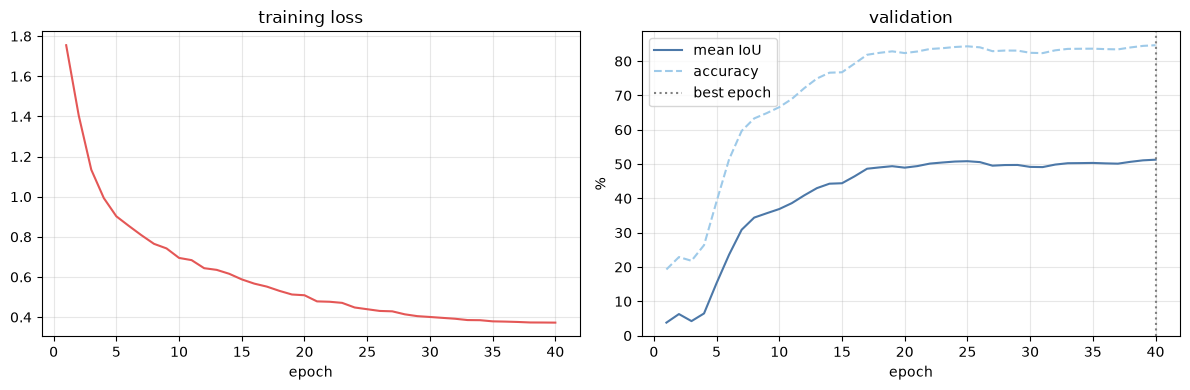

Loss falling while validation flattens or drops = overfitting. The saved model is the best epoch, not the last.


In [11]:
history = result["history"]
epochs = [h["epoch"] for h in history]
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))
left.plot(epochs, [h["loss"] for h in history], color="#E45756")
left.set_title("training loss"); left.set_xlabel("epoch"); left.grid(alpha=0.3)
right.plot(epochs, [100 * h["val_miou"] for h in history], label="mean IoU", color="#4C78A8")
right.plot(epochs, [100 * h["val_acc"] for h in history], label="accuracy",
           color="#9ECAE9", linestyle="--")
right.axvline(result["best_epoch"], color="grey", linestyle=":", label="best epoch")
right.set_title("validation"); right.set_xlabel("epoch"); right.set_ylabel("%")
right.legend(); right.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("Loss falling while validation flattens or drops = overfitting. "
      "The saved model is the best epoch, not the last.")

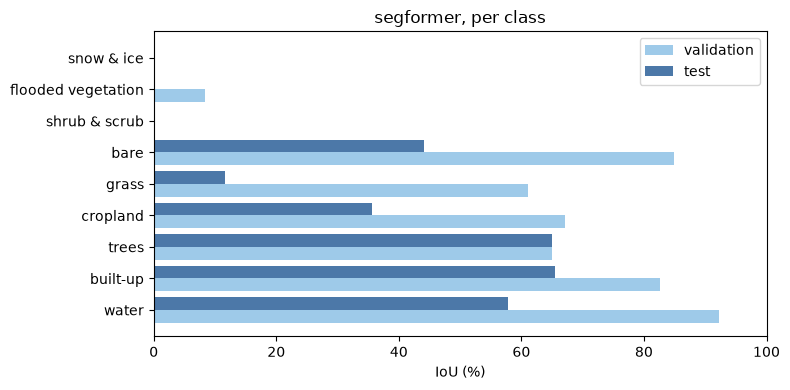

A class missing from the test bars does not occur in the test regions.


In [12]:
classes = list(result["val"]["per_class"])
v = [100 * result["val"]["per_class"][c] for c in classes]
t = [100 * result["test"]["per_class"].get(c, np.nan) for c in classes]
y = np.arange(len(classes))
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(y - 0.2, v, height=0.4, label="validation", color="#9ECAE9")
ax.barh(y + 0.2, t, height=0.4, label="test", color="#4C78A8")
ax.set_yticks(y); ax.set_yticklabels(classes); ax.set_xlim(0, 100)
ax.set_xlabel("IoU (%)"); ax.set_title(f"{NAME}, per class"); ax.legend()
plt.tight_layout(); plt.show()
print("A class missing from the test bars does not occur in the test regions.")

## Where it goes wrong - the confusion matrix

Each row is the label, each column what the model said, as a % of the row: the diagonal is what it got right, everything else is a confusion.

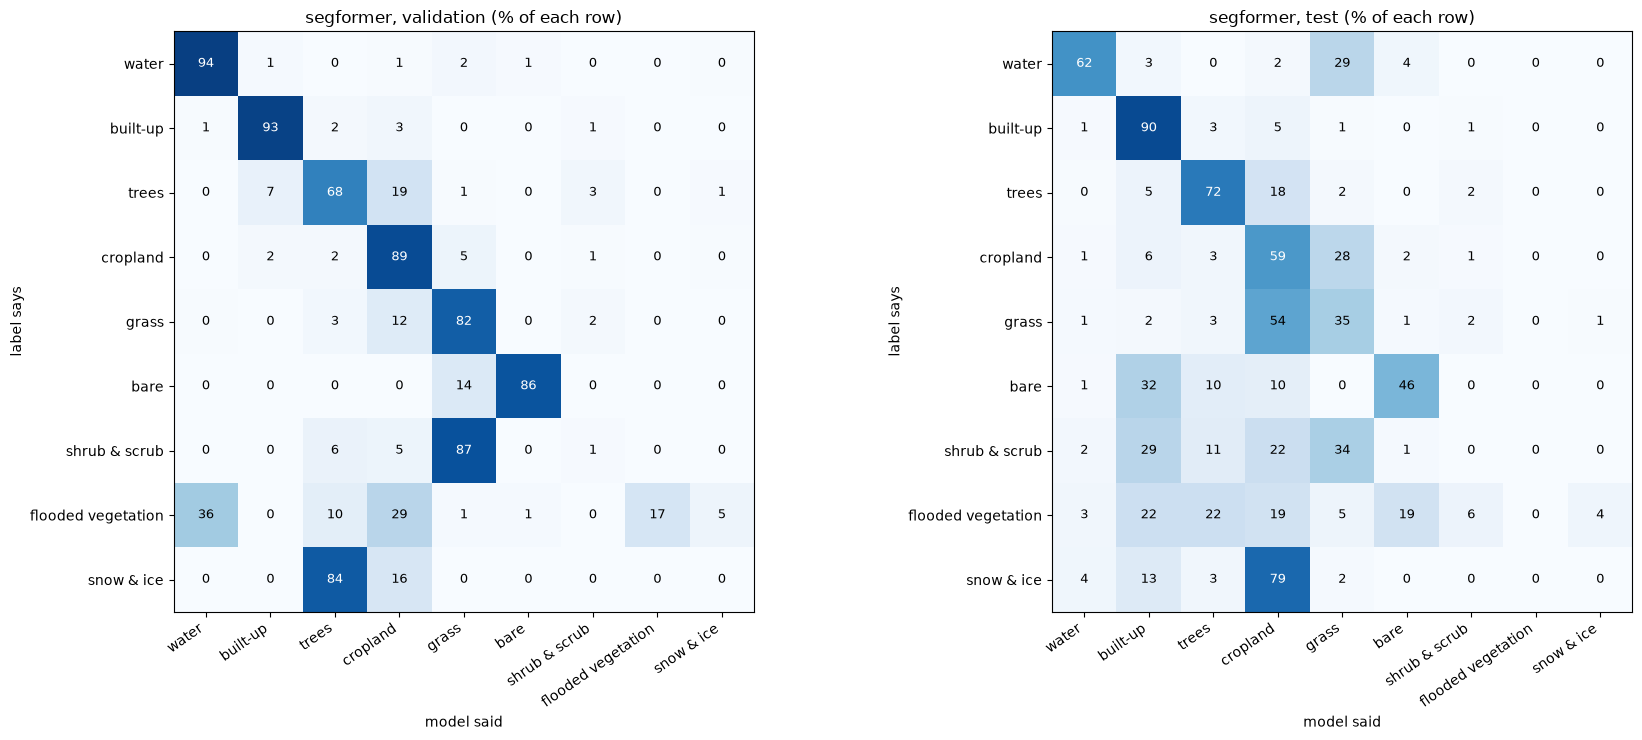

Read along a row: where does each labelled class end up? A blank row = that class
does not occur in that split.


In [13]:
full = {split: np.array(result["confusion"][split], dtype="float64") for split in ("val", "test")}
K = config.NUM_CLASSES - 1                              # the labelled classes
short = [config.CLASSES[c] for c in range(1, config.NUM_CLASSES)]
fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
for ax, split in zip(axes, ("val", "test")):
    m = full[split]
    seen = m[1:, :].sum(axis=1, keepdims=True)          # every labelled pixel of that class
    share = np.divide(m[1:, 1:], seen, out=np.full((K, K), np.nan), where=seen > 0) * 100
    ax.imshow(np.nan_to_num(share), cmap="Blues", vmin=0, vmax=100)
    for i in range(K):
        for j in range(K):
            if not np.isnan(share[i, j]):
                ax.text(j, i, f"{share[i, j]:.0f}", ha="center", va="center", fontsize=9,
                        color="white" if share[i, j] > 55 else "black")
    ax.set_xticks(range(K)); ax.set_xticklabels(short, rotation=35, ha="right")
    ax.set_yticks(range(K)); ax.set_yticklabels(short)
    ax.set_xlabel("model said"); ax.set_ylabel("label says")
    ax.set_title(f"{NAME}, {'validation' if split == 'val' else 'test'} (% of each row)")
plt.tight_layout(); plt.show()
print("Read along a row: where does each labelled class end up? A blank row = that class")
print("does not occur in that split.")

## The comparison - every run so far, split by split

Reads the saved result files and tabulates them. Compare down a column, never across.

In [14]:
results = sorted(config.OUTPUTS.glob("*_result.json"))
names = [config.CLASSES[c] for c in range(1, config.NUM_CLASSES)]
if not results:
    print("no runs finished yet")
else:
    print(f"{'model':<14}{'parameters':>12}{'validation':>12}{'test':>10}")
    print("-" * 48)
    rows = [(path, json.loads(path.read_text())) for path in results]
    for path, r in rows:
        label = r.get("model", path.stem.replace("_result", ""))
        size = f"{r['parameters']:,}" if "parameters" in r else "-"
        print(f"{label:<14}{size:>12}{100 * r['val']['mean_iou']:>11.1f}%"
              f"{100 * r['test']['mean_iou']:>9.1f}%")

    print("\ntest IoU per class")
    print(f"{'':<14}" + "".join(f"{n[:9]:>10}" for n in names))
    for path, r in rows:
        label = r.get("model", path.stem.replace("_result", ""))
        per = r["test"]["per_class"]
        print(f"{label:<14}" + "".join(
            f"{100 * per[n]:>9.1f}%" if n in per else f"{'-':>10}" for n in names))
    print("\nSame labels and the same splits for every row, so the gap between")
    print("two rows is the architecture and nothing else.")

model           parameters  validation      test
------------------------------------------------
deeplab          2,349,394       49.0%     30.3%
segformer        2,280,458       51.3%     31.1%
unet16           1,942,730       42.1%     31.1%

test IoU per class
                   water  built-up     trees  cropland     grass      bare shrub & s flooded v snow & ic
deeplab            63.6%     70.9%     65.0%     29.9%     16.5%     25.2%      0.1%      1.6%      0.0%
segformer          57.9%     65.4%     65.0%     35.6%     11.7%     44.2%      0.0%      0.0%      0.0%
unet16             77.6%     74.2%     61.6%     31.7%     15.5%     19.0%      0.2%      0.0%      0.0%

Same labels and the same splits for every row, so the gap between
two rows is the architecture and nothing else.


## Looking at the maps, not just the numbers

Four validation tiles: radar, labels and prediction side by side.

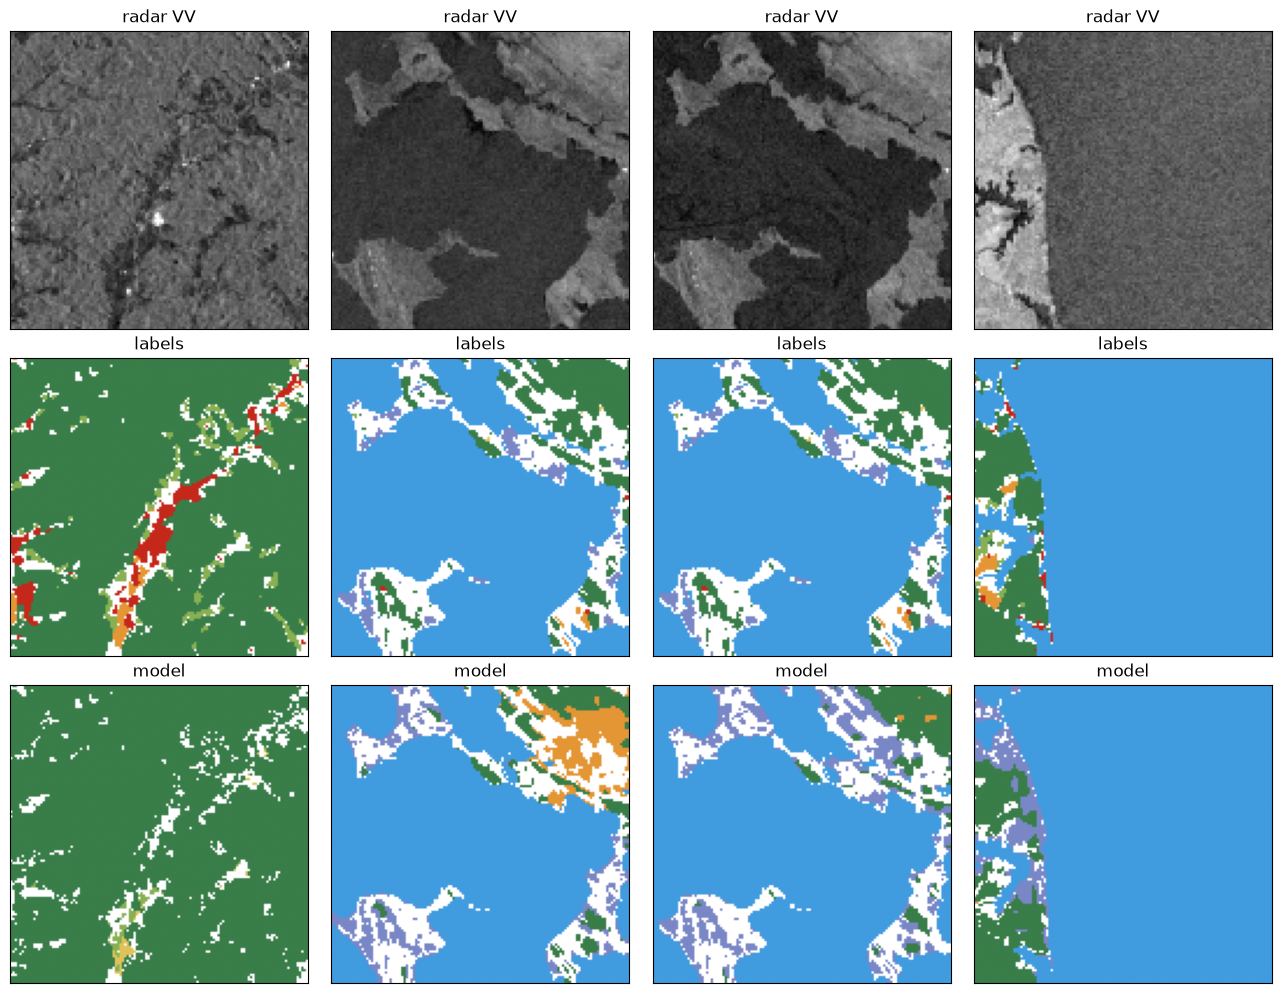

In [15]:
from matplotlib.colors import ListedColormap
# Dynamic World's own colours, in our class order (0 = unlabelled, white)
palette = ListedColormap(["#ffffff", "#419bdf", "#c4281b", "#397d49", "#e49635",
                          "#88b053", "#a59b8f", "#dfc35a", "#7a87c6", "#b39fe1"])
top = config.NUM_CLASSES - 1

net = result["net"].eval()
x, y = next(iter(DataLoader(Tiles("val", root=TILES), batch_size=4, shuffle=True)))
with torch.no_grad():
    guess = net(x.to(DEVICE)).argmax(1).cpu().numpy()
guess[y.numpy() == 0] = 0

fig, axes = plt.subplots(3, 4, figsize=(13, 10))
for i in range(4):
    axes[0, i].imshow(x[i, 0], cmap="gray"); axes[0, i].set_title("radar VV")
    axes[1, i].imshow(y[i], cmap=palette, vmin=0, vmax=top); axes[1, i].set_title("labels")
    axes[2, i].imshow(guess[i], cmap=palette, vmin=0, vmax=top); axes[2, i].set_title("model")
for a in axes.ravel():
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## Findings

Scores from the runs above, filled in once they finish. Every score is agreement with Dynamic World, not with ground truth.

| | validation | test |
|---|---|---|
| U-Net | | |
| DeepLabV3+ | | |
| SegFormer | | |